In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
upload=files.upload()
df = pd.read_excel("cleaned_data.xlsx",
                   sheet_name="Transactions")
df.head()

,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail,total_sales
0,1,2023-01-01,07:06:11,2,5,Lower Manhattan,32,3.0,Coffee,Gourmet brewed coffee,Ethiopia Rg,6.0
1,2,2023-01-01,07:08:56,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg,6.2
2,3,2023-01-01,07:14:04,2,5,Lower Manhattan,59,4.5,Drinking Chocolate,Hot chocolate,Dark chocolate Lg,9.0
3,4,2023-01-01,07:20:24,1,5,Lower Manhattan,22,2.0,Coffee,Drip coffee,Our Old Time Diner Blend Sm,2.0
4,5,2023-01-01,07:22:41,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg,6.2


In [5]:
print("dataset shape",df.shape)
print("column names")
print(df.columns.tolist())
df.info()
display(df.describe())

dataset shape (149116, 12)
column names
['transaction_id', 'transaction_date', 'transaction_time', 'transaction_qty', 'store_id', 'store_location', 'product_id', 'unit_price', 'product_category', 'product_type', 'product_detail', 'total_sales']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149116 entries, 0 to 149115
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   transaction_id    149116 non-null  int64         
 1   transaction_date  149116 non-null  datetime64[ns]
 2   transaction_time  149116 non-null  object        
 3   transaction_qty   149116 non-null  int64         
 4   store_id          149116 non-null  int64         
 5   store_location    149116 non-null  object        
 6   product_id        149116 non-null  int64         
 7   unit_price        149116 non-null  float64       
 8   product_category  149116 non-null  object        
 9   product_type      149116 non-null 

,transaction_id,transaction_date,transaction_qty,store_id,product_id,unit_price,total_sales
count,149116.000000,149116,149116.000000,149116.000000,149116.000000,149116.000000,149116.000000
mean,74737.371872,2023-04-15 11:50:32.173609984,1.438276,5.342063,47.918607,3.382219,4.686367
min,1.000000,2023-01-01 00:00:00,1.000000,3.000000,1.000000,0.800000,0.800000
25%,37335.750000,2023-03-06 00:00:00,1.000000,3.000000,33.000000,2.500000,3.000000
50%,74727.500000,2023-04-24 00:00:00,1.000000,5.000000,47.000000,3.000000,3.750000
75%,112094.250000,2023-05-30 00:00:00,2.000000,8.000000,60.000000,3.750000,6.000000
max,149456.000000,2023-06-30 00:00:00,8.000000,8.000000,87.000000,45.000000,360.000000
std,43153.600016,NaN,0.542509,2.074241,17.930020,2.658723,4.227099


In [6]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())
# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())
# Check duplicate transaction IDs
print("Duplicate transaction IDs:",
      df["transaction_id"].duplicated().sum())

Missing values:
transaction_id      0
transaction_date    0
transaction_time    0
transaction_qty     0
store_id            0
store_location      0
product_id          0
unit_price          0
product_category    0
product_type        0
product_detail      0
total_sales         0
dtype: int64

Duplicate rows: 0
Duplicate transaction IDs: 0


In [7]:
total_revenue = df["total_sales"].sum()
total_transactions = df["transaction_id"].nunique()
total_quantity = df["transaction_qty"].sum()
average_transaction = total_revenue / total_transactions
print("Total Revenue:", round(total_revenue, 2))
print("Total Transactions:", total_transactions)
print("Total Items Sold:", total_quantity)
print("Average Transaction Value:", round(average_transaction, 2))

Total Revenue: 698812.33
Total Transactions: 149116
Total Items Sold: 214470
Average Transaction Value: 4.69


In [8]:
# Convert transaction_date to datetime
df["transaction_date"] = pd.to_datetime(df["transaction_date"])

# Extract month
df["month"] = df["transaction_date"].dt.month_name()

# Calculate monthly revenue
monthly_sales = df.groupby("month")["total_sales"].sum()

print(monthly_sales)

month
April       118941.08
February     76145.19
January      81677.74
June        166485.88
March        98834.68
May         156727.76
Name: total_sales, dtype: float64


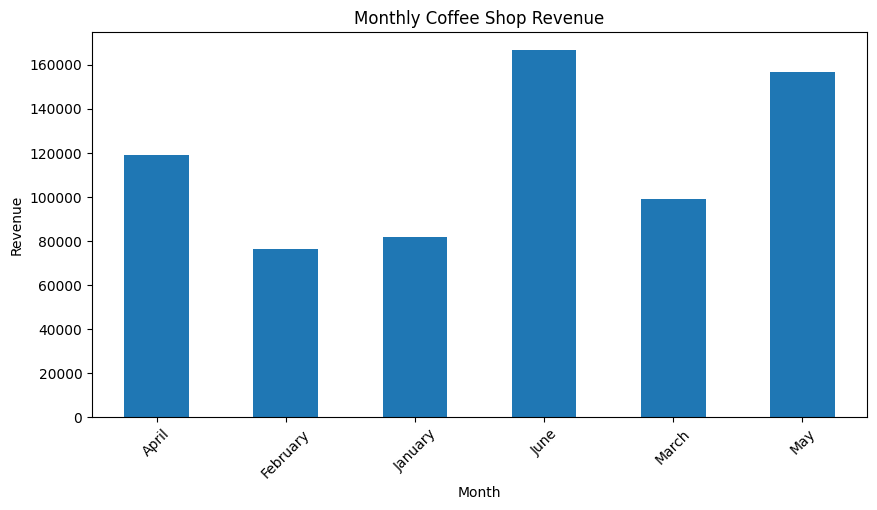

In [9]:
plt.figure(figsize=(10, 5))
monthly_sales.plot(kind="bar")
plt.title("Monthly Coffee Shop Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)

plt.show()

In [12]:
store_sales=df.groupby("store_location")["total_sales"].sum()
print(store_sales)

store_location
Astoria            232243.91
Hell's Kitchen     236511.17
Lower Manhattan    230057.25
Name: total_sales, dtype: float64


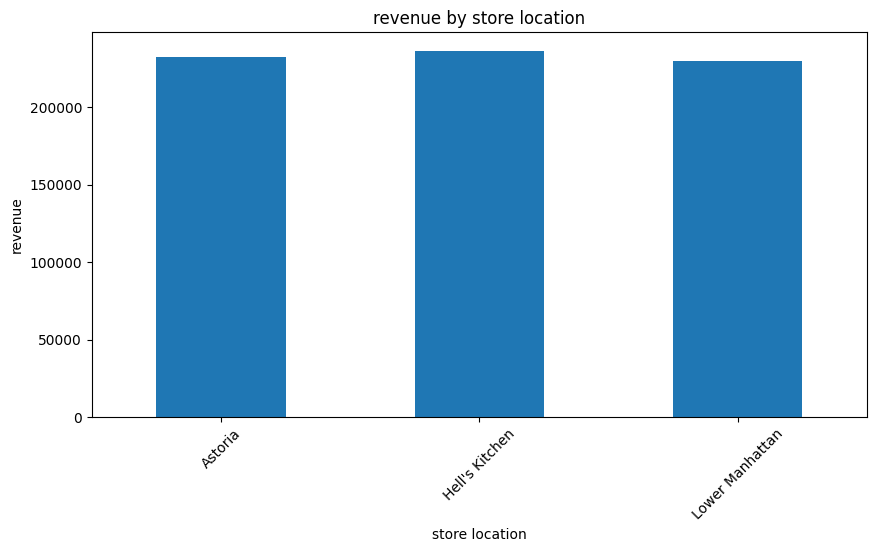

In [16]:
plt.figure(figsize=(10,5))
store_sales.plot(kind="bar")
plt.title("revenue by store location")
plt.xlabel("store location")
plt.ylabel("revenue")
plt.xticks(rotation=45)
plt.show()

In [17]:
category_sales=df.groupby("product_category")["total_sales"].sum()
print(category_sales)

product_category
Bakery                 82315.64
Branded                13607.00
Coffee                269952.45
Coffee beans           40085.25
Drinking Chocolate     72416.00
Flavours                8408.80
Loose Tea              11213.60
Packaged Chocolate      4407.64
Tea                   196405.95
Name: total_sales, dtype: float64


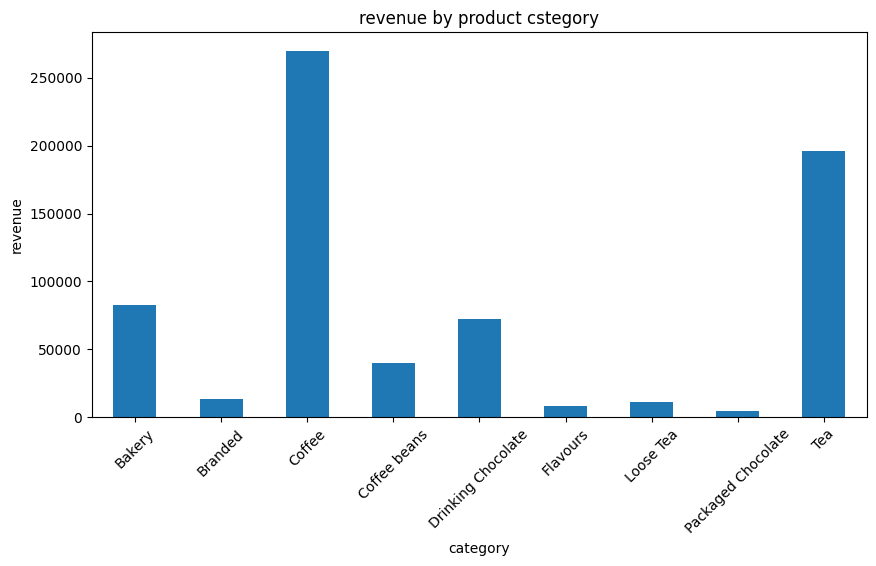

In [18]:
plt.figure(figsize=(10,5))
category_sales.plot(kind='bar')
plt.title("revenue by product cstegory")
plt.xlabel("category")
plt.ylabel("revenue")
plt.xticks(rotation=45)
plt.show()